In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from implementation import *

In [ ]:
#split data in train and test
seed = 42
data, header = load_data('data/x_train.csv', header=True, intercept=True)
y, _ = load_data('data/y_train.csv')
x_train, x_test, y_train, y_test = split_data(data, y, ratio=0.6, seed=seed)


In [ ]:
x_norm, mean, std = normalize(x_train)
x_1, header_1, ind_nan = remove_col_full_nan(x_norm, header, threshold = 0.5)
x_2, header_2, ind_const = const_column(x_1, header_1, threshold=0.97)


c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:73: RuntimeWarning: invalid value encountered in divide
  norm_x = (x-mean) / std


In [ ]:
x_3, header_3, corr_rem = pairwise_corr(x_2, header_2, threshold=0.95)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]




In [9]:
plot_features(x_3, header_3)

In [10]:
data_without_nan = replace_nan(x_3)

(0.1382265951255597,
 0.13823075866386506,
 array([0.13818589], dtype=float32),
 array([0.22914742]))

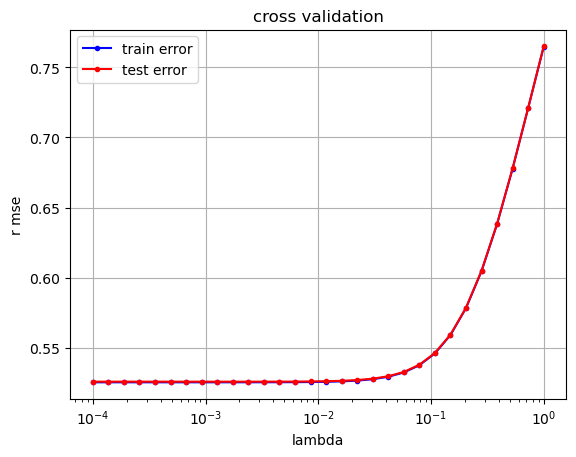

In [19]:
from implementation import *
#mean squared error, gradient descent
col = data_without_nan.shape[1]
obs = data_without_nan.shape[0]
w_gd, loss_gd = mean_squared_error_gd(y_train.squeeze(), data_without_nan, np.zeros(col), 40, 0.15)

#mean squared error, stochastic gradient descent
w_sgd, loss_sgd = mean_squared_error_sgd(y_train.squeeze(), data_without_nan, np.zeros(col), 40, 0.15)

#least squared (find best lambda)
w_ls, loss_ls = least_squares(y_train, data_without_nan)

#ridge regression
lambdas = np.logspace(-4, 0, 30)
best_loss, best_lambda = cross_validation(y_train, data_without_nan, 7, lambdas)
w_ridge, loss_ridge = ridge_regression(y_train, data_without_nan, best_lambda)

loss_gd, loss_sgd, loss_ls, loss_ridge

In [38]:
w_log, log_loss = gd_logistic_loss_pen(y_train, data_without_nan, np.zeros(data_without_nan.shape[1]), 30, 0.1, 0.05)
log_loss

c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:373: RuntimeWarning: overflow encountered in exp
  der_ln = 1 / (1 + point_y*y_pred)


0.6213440716702532

In [26]:
#result 

#preprocess test data
norm_test = (x_test - mean) / std

#col remove
test_1 = np.delete(norm_test, ind_nan, axis = 1)
test_2 = np.delete(test_1, ind_const, axis = 1)
test_3 = np.delete(test_2, corr_rem, axis= 1)
test_4 = replace_nan(test_3)


C:\Users\yvanb\AppData\Local\Temp\ipykernel_30652\536403926.py:4: RuntimeWarning: invalid value encountered in divide
  norm_test = (x_test - mean) / std


In [39]:
#prediction

#mse, gd
pred_gd = test_4.dot(w_gd)
print(pred_gd.shape)
#mse, sgd
pred_sgd = test_4.dot(w_sgd)
print(pred_sgd.shape)
#ls
pred_ls = test_4.dot(w_ls).squeeze()
print(pred_ls.shape)
#ridge
pred_ridge = test_4.dot(w_ridge).squeeze()
print(pred_ridge.shape)
#logistic 
pred_log = test_4.dot(w_log).squeeze()
print(pred_log.shape)

(131254,)
(131254,)
(131254,)
(131254,)
(131254,)


In [41]:
from implementation import *
#Calculate the accuracy of prediction
nbre_obs = len(y_test)
#gd
bin_gd = threshold_prediction(pred_gd)
acc_gd = accuracy(y_test, bin_gd)
print(acc_gd)
#sgd
bin_sgd = threshold_prediction(pred_sgd)
acc_sgd = accuracy(y_test, bin_sgd)
print(acc_sgd)
#ls
bin_ls = threshold_prediction(pred_ls)
acc_ls = accuracy(y_test, bin_ls)
print(acc_ls)
#ridge
bin_ridge = threshold_prediction(pred_ridge)
acc_ridge = accuracy(y_test, bin_ridge)
print(acc_ridge)
#logistic
bin_log = threshold_prediction(pred_log)
acc_log = accuracy(y_test, bin_log)
print(acc_log)

0.9104702466132482
0.910463990493899
0.9105265516873899
0.9029253666782436
0.7339037902238362


In [54]:
from implementation import*
lambdas = np.logspace(-5, 0, 4)
gammas = np.logspace(-5, 0, 4)
lambda_, gamma, log_loss = cross_validation_log(y_train, data_without_nan,5 , lambdas, gammas)

w, loss = gd_logistic_loss_pen(y_train, data_without_nan, np.zeros(data_without_nan.shape[1]), 10, lambda_, gamma)
pred = test_4.dot(w).squeeze()
bin_ = threshold_prediction(pred)
acc = accuracy(y_test, bin_)
print(acc)
print(lambda_, gamma)

c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:487: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-t))


KeyboardInterrupt: 

In [ ]:
from implementation import *
loss_best = np.inf
w = np.zeros(data_without_nan.shape[1])
for lambda_ in (np.logspace(1e-5, 0, 6)) :
    w_log, loss = newton_log_pen(y_train, data_without_nan, w, 30, lambda_)
    print(loss)
    if loss < loss_best :
        lost_best = loss
        w = w_log
pred = test_4.dot(w_log).squeeze()
bin_ = threshold_prediction(pred)
acc = accuracy(y_test, bin_)
print(acc)

0.6095501129323124
0.6095498093961124
0.6095495058590525
0.6095492023211362
0.6095488987823637
0.6095485952427352
